# Which attributes to train on

`readmit_df` is one row per hospital stay. The column names are CMS DE-SynPUF codes (`SP_CHRNKIDN`, `BENE_HI_CVRAGE_TOT_MONS`, …). This notebook does two things:

1. Says what each attribute means and renames it.
2. Decides which renamed columns a **decision tree** and a **random forest** should see.

The label is whether the next inpatient admission falls within 30 days of discharge. About 9.5% of stays are readmissions, so a model that always predicts "no" is already about 90% accurate. Accuracy is the wrong way to compare feature sets. The comparisons below use ROC-AUC and average precision.

Stays are split **by patient** (20% of patients held out). The same person can have several stays, and a random row split would put those stays on both sides.

This is feature selection, not the tuned final model. Tree depth and leaf size are fixed so every feature set is compared under the same settings.


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, export_text

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 160)

CANDIDATES = [
    Path("cleaned_data/readmit_df.parquet"),
    Path("notebooks/cleaned_data/readmit_df.parquet"),
]
DATA_PATH = next(p for p in CANDIDATES if p.exists())
readmit = pd.read_parquet(DATA_PATH)
print(f"Loaded {DATA_PATH}  ->  {readmit.shape[0]:,} stays, {readmit.shape[1]} columns")
print(f"Patients: {readmit['DESYNPUF_ID'].nunique():,}")
print(f"30-day readmission rate: {readmit['READMIT_30'].mean():.2%}")


Loaded cleaned_data/readmit_df.parquet  ->  63,874 stays, 49 columns
Patients: 37,658
30-day readmission rate: 9.55%


## What the columns mean

The names below are the ones to use from here on. `decision` is the training decision, justified in the next sections.

Same-year chronic flags (`heart_failure`, `copd`, and the rest) are the strongest predictors in this file. They are also the main leakage risk: CMS sets them for the **whole discharge year**, so a flag can be turned on by care that happens after the stay, including the readmission itself. `chronic_condition_count_prior_year` is the same count from the previous calendar year, which cannot see the readmission. It is missing for about 40% of stays (there is no 2007 file, so every 2008 discharge is missing). This scikit-learn version can send missing values down their own branch, so those rows do not have to be dropped or filled.


In [3]:
# original CMS name, readable name, meaning, decision, why
ATTRIBUTES = [
    ("STAY_ID", "stay_id", "Id of this hospital stay.", "drop", "Unique per row. An identifier, not a predictor."),
    ("DESYNPUF_ID", "patient_id", "Synthetic patient id.", "split only", "Use it to keep a patient entirely in train or entirely in test. Do not pass it to the model."),
    ("ADMSN_DT", "admission_date", "Admission date of the stay (earliest claim if several claims were merged).", "drop", "A raw date lets a tree memorize the calendar. The label is also built from these dates."),
    ("DSCHRG_DT", "discharge_date", "Discharge date of the stay.", "drop", "Same problem as the admission date."),
    ("READMIT_30", "readmitted_30_days", "1 if the next inpatient admission is within 30 days of discharge, else 0.", "target", "This is the label."),
    ("DAYS_TO_NEXT_ADMIT", "days_to_next_admission", "Days from this discharge to the next admission. Missing if there is no later admission.", "drop", "The label is exactly this number cut at 30. Training on it is leakage."),
    ("PRVDR_NUM", "hospital_id", "Hospital (provider) id of the first claim in the stay.", "drop", "2,666 hospitals. A train-only readmission rate for the hospital raised train AUC and lowered test AUC."),
    ("CLM_DRG_CD", "drg_code", "Diagnosis-related group of the first claim: the billing category for why the patient was admitted.", "drop", "739 codes. One-hot encoding and a smoothed train-only rate both failed to raise holdout AUC."),
    ("DRG_UNGROUPED", "drg_ungrouped", "The DRG was missing or not a real group.", "drop", "True on about 0.6% of stays. Too rare for a stable split."),
    ("ADMTNG_ICD9_DGNS_CD", "admitting_diagnosis_code", "Full ICD-9 admitting diagnosis.", "drop", "2,259 codes, many of them rare. The 3-character category was tested instead and did not help."),
    ("ICD9_DGNS_CD_1", "principal_diagnosis_code", "Full ICD-9 principal diagnosis.", "drop", "2,698 codes. Same result as the admitting code."),
    ("DX1_CAT", "principal_diagnosis_category", "First 3 characters of the principal ICD-9 code (4 characters when the code starts with E).", "drop", "646 categories, and it matches the full code's prefix. Adding it did not raise holdout AUC."),
    ("ADMTNG_DX_CAT", "admitting_diagnosis_category", "Same grouping of the admitting diagnosis. It matches the principal category on only about 36% of stays.", "drop", "Still no holdout gain once the clinical flags and prior-use counts are in the model."),
    ("N_DX", "diagnosis_count", "How many diagnosis code slots were filled on the first claim.", "use", "Small numeric summary of how many diagnoses were recorded. Known at discharge."),
    ("N_PRCDR", "procedure_count", "How many procedure code slots were filled on the first claim.", "use", "Same idea for procedures. Known at discharge."),
    ("TOTAL_PMT", "total_payment", "Sum of Medicare payments for the claims in the stay, in dollars.", "use", "Known once the stay is billed. Trees do not need this scaled. Drop it only if the model must run at admission, before payment is known."),
    ("N_CLAIMS", "claims_in_stay", "How many inpatient claims were merged into this stay.", "drop", "96.6% of stays are a single claim."),
    ("ANY_PMT_NEGATIVE", "any_negative_payment", "At least one claim in the stay had a negative payment (an adjustment).", "drop", "True on about 0.09% of stays."),
    ("ADMSN_BEFORE_STUDY", "admitted_before_2008", "The admission date is in late 2007, before the 2008 start of the beneficiary files.", "drop", "True on about 0.3% of stays."),
    ("LOS_DAYS", "length_of_stay_days", "Discharge date minus admission date, in days. Same-day stays are 0.", "use", "Known at discharge and used by the forest. Drop it for an admission-time model."),
    ("SEX", "sex", "Sex recorded on the beneficiary file. M or F.", "use", "Almost no mutual information with readmission in this sample. Kept because it is a standard demographic and costs one split."),
    ("RACE", "race", "Race recorded on the beneficiary file: White, Black, Hispanic, or Other.", "use", "Same reason as sex."),
    ("SP_STATE_CODE", "state_code", "SSA state code of the patient.", "drop", "52 states. Adding it did not change holdout AUC."),
    ("AGE", "age_at_admission", "Age in years at admission. Birth dates in this file are only known to the month.", "use", "The forest uses it. The linear correlation with the label is near zero; the tree can still split on age bands."),
    ("ESRD", "end_stage_renal_disease", "1 if the patient had end-stage renal disease in the discharge year.", "use", "About 25% of stays. A real clinical flag, not a near-constant."),
    ("N_CHRONIC", "chronic_condition_count", "How many of the 11 chronic-condition flags are 1. It is exactly their sum.", "drop", "Redundant with the flags. A forest with the flags plus this count did not beat the flags alone."),
    ("ZERO_COVERAGE", "zero_coverage_months", "1 if every coverage column that year was 0.", "drop", "True on about 0.2% of stays."),
    ("BENE_HI_CVRAGE_TOT_MONS", "part_a_coverage_months", "Months of Medicare Part A (hospital) coverage in the discharge year. 0 to 12.", "drop", "98.3% of stays are 12. Almost no variation to split on."),
    ("BENE_SMI_CVRAGE_TOT_MONS", "part_b_coverage_months", "Months of Medicare Part B (physician) coverage in the discharge year. 0 to 12.", "drop", "97.5% of stays are 12."),
    ("BENE_HMO_CVRAGE_TOT_MONS", "hmo_coverage_months", "Months of HMO coverage in the discharge year. 0 to 12.", "use", "Varies (about 71% are 0). Describes the kind of coverage, which is known for that year."),
    ("PLAN_CVRG_MOS_NUM", "part_d_coverage_months", "Months of Medicare Part D (prescription drug) coverage in the discharge year. 0 to 12.", "use", "Varies (about 73% are 12)."),
    ("SP_ALZHDMTA", "alzheimers", "1 if Alzheimer's or dementia was flagged for the discharge year.", "use", "One of the 11 chronic flags. See the leakage note under the dictionary."),
    ("SP_CHF", "heart_failure", "1 if heart failure was flagged for the discharge year.", "use", "Readmission is about 4.6% without this flag and about 11.5% with it."),
    ("SP_CHRNKIDN", "chronic_kidney_disease", "1 if chronic kidney disease was flagged for the discharge year.", "use", "Readmission is about 5.4% without this flag and about 12.4% with it. Highest flag importance."),
    ("SP_CNCR", "cancer", "1 if cancer was flagged for the discharge year.", "use", "One of the 11 chronic flags."),
    ("SP_COPD", "copd", "1 if chronic obstructive pulmonary disease was flagged for the discharge year.", "use", "Readmission is about 6.2% without this flag and about 13.1% with it."),
    ("SP_DEPRESSN", "depression", "1 if depression was flagged for the discharge year.", "use", "One of the 11 chronic flags."),
    ("SP_DIABETES", "diabetes", "1 if diabetes was flagged for the discharge year.", "use", "One of the 11 chronic flags."),
    ("SP_ISCHMCHT", "ischemic_heart_disease", "1 if ischemic heart disease was flagged for the discharge year.", "use", "One of the 11 chronic flags."),
    ("SP_OSTEOPRS", "osteoporosis", "1 if osteoporosis was flagged for the discharge year.", "use", "One of the 11 chronic flags."),
    ("SP_RA_OA", "rheumatoid_or_osteoarthritis", "1 if rheumatoid arthritis or osteoarthritis was flagged for the discharge year.", "use", "One of the 11 chronic flags."),
    ("SP_STRKETIA", "stroke_or_tia", "1 if stroke or transient ischemic attack was flagged for the discharge year.", "use", "One of the 11 chronic flags."),
    ("OBS_HISTORY_DAYS", "observed_history_days", "How many days of claims we can see before this admission, capped at 365.", "drop", "Mostly a marker of whether the stay is early in the 2008–2010 file. Holdout AUC did not change when it was removed."),
    ("PRIOR_IP_STAYS_365", "prior_inpatient_stays_365d", "Earlier hospital stays whose discharge was in the 365 days before this admission.", "use", "Readmission rises from about 8.5% with no prior stay to about 14.5% with 3 or more. Uses only earlier dates, so it is not leakage."),
    ("PRIOR_OP_VISITS_365", "prior_outpatient_visits_365d", "Outpatient claims in the 365 days before admission.", "use", "Prior utilization. Only visits dated before the admission."),
    ("PRIOR_OP_VISITS_30", "prior_outpatient_visits_30d", "Outpatient claims in the 30 days before admission.", "use", "Recent outpatient use. Correlation with the 365-day count is only about 0.42, so it is not a copy of that column."),
    ("PRIOR_OP_PMT_365", "prior_outpatient_payment_365d", "Total outpatient Medicare payment in the 365 days before admission, in dollars.", "use", "The forest ranks this among the top numeric features."),
    ("PRIOR_ER_VISITS_365", "prior_er_visits_365d", "Outpatient claims in the 365 days before admission that were emergency-room visits (HCPCS 99281–99285).", "use", "Prior emergency use. Only visits dated before the admission."),
    ("N_CHRONIC_PREV_YEAR", "chronic_condition_count_prior_year", "How many of the 11 chronic conditions were flagged in the previous calendar year.", "use", "Leakage-safer illness burden. Missing when the patient has no prior-year record. The forest gives this column the largest importance."),
]

attribute_dict = pd.DataFrame(
    ATTRIBUTES,
    columns=["original_name", "name", "meaning", "decision", "why"],
)
assert attribute_dict["original_name"].is_unique
assert attribute_dict["name"].is_unique
assert set(attribute_dict["original_name"]) == set(readmit.columns)

rename = dict(zip(attribute_dict["original_name"], attribute_dict["name"]))
df = readmit.rename(columns=rename)

order = {"target": 0, "use": 1, "split only": 2, "drop": 3}
shown = attribute_dict.assign(_ord=attribute_dict["decision"].map(order)).sort_values(["_ord", "name"]).drop(columns="_ord")
print(shown["decision"].value_counts().to_string())
shown


use           27
drop          20
target         1
split only     1


,original_name,name,meaning,decision,why
4,READMIT_30,readmitted_30_days,"1 if the next inpatient admission is within 30 days of discharge, else 0.",target,This is the label.
23,AGE,age_at_admission,Age in years at admission. Birth dates in this file are only known to the month.,use,The forest uses it. The linear correlation with the label is near zero; the tree can still split on age bands.
31,SP_ALZHDMTA,alzheimers,1 if Alzheimer's or dementia was flagged for the discharge year.,use,One of the 11 chronic flags. See the leakage note under the dictionary.
34,SP_CNCR,cancer,1 if cancer was flagged for the discharge year.,use,One of the 11 chronic flags.
48,N_CHRONIC_PREV_YEAR,chronic_condition_count_prior_year,How many of the 11 chronic conditions were flagged in the previous calendar year.,use,Leakage-safer illness burden. Missing when the patient has no prior-year record. The forest gives this column the la...
33,SP_CHRNKIDN,chronic_kidney_disease,1 if chronic kidney disease was flagged for the discharge year.,use,Readmission is about 5.4% without this flag and about 12.4% with it. Highest flag importance.
35,SP_COPD,copd,1 if chronic obstructive pulmonary disease was flagged for the discharge year.,use,Readmission is about 6.2% without this flag and about 13.1% with it.
36,SP_DEPRESSN,depression,1 if depression was flagged for the discharge year.,use,One of the 11 chronic flags.
37,SP_DIABETES,diabetes,1 if diabetes was flagged for the discharge year.,use,One of the 11 chronic flags.
13,N_DX,diagnosis_count,How many diagnosis code slots were filled on the first claim.,use,Small numeric summary of how many diagnoses were recorded. Known at discharge.


## Columns that are not features

Four rules, before looking at model scores:

- **The label and anything that defines it.** `days_to_next_admission` is the quantity `readmitted_30_days` is cut from.
- **Identifiers and raw dates.** `patient_id` is for the split only. A date column lets a tree split on a particular week.
- **Copies.** `chronic_condition_count` is the sum of the 11 flags. Training on the sum and the flags gives the tree two names for one fact.
- **Near-constants.** A flag that is true on well under 1% of stays, or a coverage column that is 12 for more than 97% of stays, does not give a stable split.

Diagnosis codes, DRG, hospital, and state are not near-constants, but they have hundreds or thousands of levels. A tree encodes a category as "code ≤ k", which is an arbitrary order, or we one-hot them into hundreds of columns. The next section measures whether that complexity is worth it.


In [4]:
TARGET = "readmitted_30_days"
GROUP = "patient_id"
CHRONIC_FLAGS = [
    "alzheimers", "heart_failure", "chronic_kidney_disease", "cancer", "copd",
    "depression", "diabetes", "ischemic_heart_disease", "osteoporosis",
    "rheumatoid_or_osteoarthritis", "stroke_or_tia",
]
RECOMMENDED = [
    "age_at_admission", "sex", "race",
    "length_of_stay_days", "diagnosis_count", "procedure_count", "total_payment",
    "end_stage_renal_disease",
    "hmo_coverage_months", "part_d_coverage_months",
    "prior_inpatient_stays_365d", "prior_outpatient_visits_365d", "prior_outpatient_visits_30d",
    "prior_outpatient_payment_365d", "prior_er_visits_365d",
    "chronic_condition_count_prior_year",
    *CHRONIC_FLAGS,
]

y = df[TARGET].astype(int)
groups = df[GROUP]
train_idx, test_idx = next(
    GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0).split(df, y, groups)
)
overlap = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
print(f"Train stays {len(train_idx):,}   test stays {len(test_idx):,}   shared patients {len(overlap)}")
print(f"Test readmission rate {y.iloc[test_idx].mean():.2%}  (average precision of predicting the base rate)")


def bucket_rare(all_values, min_count=30):
    """Collapse levels that appear fewer than min_count times in the training patients."""
    filled = all_values.fillna("MISSING").astype(str)
    keep = set(filled.iloc[train_idx].value_counts().loc[lambda s: s >= min_count].index)
    return filled.where(filled.isin(keep), "OTHER")


def smoothed_rate(all_keys, prior_strength=20):
    """Train-only mean of the label for each level, shrunk toward the training base rate."""
    keys = all_keys.fillna("MISSING").astype(str)
    tab = pd.DataFrame({"key": keys.iloc[train_idx], "y": y.iloc[train_idx].to_numpy()})
    base = tab["y"].mean()
    stats = tab.groupby("key")["y"].agg(["sum", "count"])
    rate = (stats["sum"] + prior_strength * base) / (stats["count"] + prior_strength)
    return keys.map(rate).fillna(base).astype(float)


def score_feature_set(frame):
    cat_cols = [c for c in frame.columns if frame[c].dtype == object or str(frame[c].dtype) == "category"]
    num_cols = [c for c in frame.columns if c not in cat_cols]
    pre = ColumnTransformer(
        [
            ("num", "passthrough", num_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ]
    )
    X_train = pre.fit_transform(frame.iloc[train_idx])
    X_test = pre.transform(frame.iloc[test_idx])
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    forest = RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=40,
        class_weight="balanced_subsample",
        random_state=0,
        n_jobs=-1,
    )
    forest.fit(X_train, y_train)
    proba = forest.predict_proba(X_test)[:, 1]
    proba_train = forest.predict_proba(X_train)[:, 1]
    return {
        "input_columns": frame.shape[1],
        "encoded_columns": X_train.shape[1],
        "test_auc": roc_auc_score(y_test, proba),
        "test_average_precision": average_precision_score(y_test, proba),
        "train_auc": roc_auc_score(y_train, proba_train),
    }, forest, pre


base = df[RECOMMENDED]
variants = {"recommended": base}

variants["recommended + state"] = base.join(df["state_code"])
variants["recommended + DRG (rare codes collapsed)"] = base.assign(drg_code=bucket_rare(df["drg_code"]))
variants["recommended + principal diagnosis category"] = base.assign(
    principal_diagnosis_category=bucket_rare(df["principal_diagnosis_category"])
)
variants["recommended + admitting diagnosis category"] = base.assign(
    admitting_diagnosis_category=bucket_rare(df["admitting_diagnosis_category"])
)
variants["recommended + hospital readmission rate"] = base.assign(hospital_rate=smoothed_rate(df["hospital_id"]))
variants["recommended + DRG readmission rate"] = base.assign(drg_rate=smoothed_rate(df["drg_code"]))
variants["recommended + observed history"] = base.join(df["observed_history_days"])

no_flags = [c for c in RECOMMENDED if c not in CHRONIC_FLAGS]
variants["without chronic flags"] = df[no_flags]
variants["count instead of flags"] = df[no_flags + ["chronic_condition_count"]]
variants["flags and the count"] = df[RECOMMENDED + ["chronic_condition_count"]]

rows = []
fitted = {}
for name, frame in variants.items():
    metrics, forest, pre = score_feature_set(frame)
    rows.append({"feature set": name, **metrics})
    fitted[name] = (forest, pre, frame)
    print(f"{name}: test AUC {metrics['test_auc']:.3f}")

comparison = pd.DataFrame(rows).set_index("feature set")
comparison.round(3)


Train stays 51,057   test stays 12,817   shared patients 0
Test readmission rate 9.62%  (average precision of predicting the base rate)
recommended: test AUC 0.701
recommended + state: test AUC 0.702
recommended + DRG (rare codes collapsed): test AUC 0.697
recommended + principal diagnosis category: test AUC 0.701
recommended + admitting diagnosis category: test AUC 0.699
recommended + hospital readmission rate: test AUC 0.660
recommended + DRG readmission rate: test AUC 0.685
recommended + observed history: test AUC 0.702
without chronic flags: test AUC 0.659
count instead of flags: test AUC 0.692
flags and the count: test AUC 0.700


,input_columns,encoded_columns,test_auc,test_average_precision,train_auc
feature set,,,,,
recommended,27,31,0.701,0.181,0.794
recommended + state,28,83,0.702,0.183,0.774
recommended + DRG (rare codes collapsed),28,594,0.697,0.179,0.718
recommended + principal diagnosis category,28,227,0.701,0.181,0.746
recommended + admitting diagnosis category,28,184,0.699,0.179,0.752
recommended + hospital readmission rate,28,32,0.660,0.161,0.834
recommended + DRG readmission rate,28,32,0.685,0.167,0.816
recommended + observed history,28,32,0.702,0.179,0.796
without chronic flags,16,20,0.659,0.153,0.767


## What the comparison says

Read the table as a difference from the **recommended** row. A useful extra column raises test AUC. A column that raises train AUC and lowers test AUC is being memorized.

- Collapsing rare DRGs or diagnosis categories into `OTHER`, then one-hot encoding them, does not beat the recommended set. A smoothed readmission rate for the DRG, fit on the training patients only, makes the forest look better on the training patients and worse on the held-out patients.
- The hospital rate does the same thing, more sharply. Hospital id does not belong in these models.
- State does not move test AUC.
- `observed_history_days` does not move test AUC once the prior-use counts are present.
- Removing the 11 chronic flags drops test AUC by several points. Replacing the flags with their sum gets most of that back, and adding the sum on top of the flags does not. Keep the flags, not the sum. The flags are what a tree can explain ("kidney disease: yes").
- The prior-year count stays in the recommended set. It is not a copy of the same-year flags: it is last year's total, and it is the column the forest relies on most.

`class_weight` is set so the 9.5% readmission class affects the splits. The same weights are used for every row of the table.


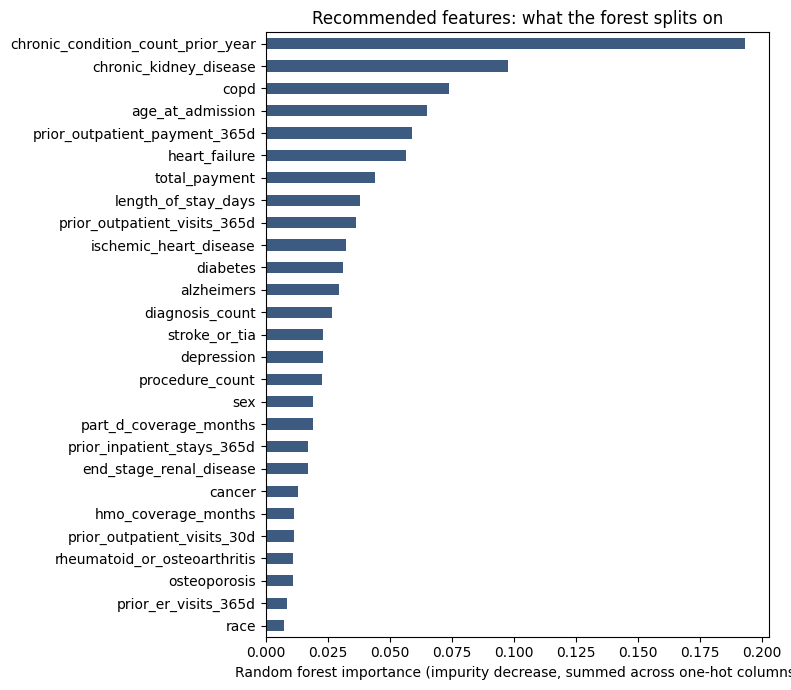

Depth-3 tree on the recommended features: test AUC 0.675
|--- chronic_condition_count_prior_year <= 6.50
|   |--- chronic_kidney_disease <= 0.50
|   |   |--- heart_failure <= 0.50
|   |   |   |--- class: 0
|   |   |--- heart_failure >  0.50
|   |   |   |--- class: 0
|   |--- chronic_kidney_disease >  0.50
|   |   |--- copd <= 0.50
|   |   |   |--- class: 0
|   |   |--- copd >  0.50
|   |   |   |--- class: 1
|--- chronic_condition_count_prior_year >  6.50
|   |--- chronic_kidney_disease <= 0.50
|   |   |--- copd <= 0.50
|   |   |   |--- class: 0
|   |   |--- copd >  0.50
|   |   |   |--- class: 1
|   |--- chronic_kidney_disease >  0.50
|   |   |--- copd <= 0.50
|   |   |   |--- class: 1
|   |   |--- copd >  0.50
|   |   |   |--- class: 1



,mutual_information
chronic_kidney_disease,0.0076
copd,0.0068
heart_failure,0.0064
chronic_condition_count_prior_year,0.0053
ischemic_heart_disease,0.0039
alzheimers,0.0037
diabetes,0.0037
end_stage_renal_disease,0.0034
stroke_or_tia,0.0028
depression,0.0028


In [5]:
forest, pre, frame = fitted["recommended"]
importances = pd.Series(forest.feature_importances_, index=pre.get_feature_names_out())

def parent_feature(encoded_name):
    name = encoded_name.split("__", 1)[-1]
    if name.startswith("sex_"):
        return "sex"
    if name.startswith("race_"):
        return "race"
    return name

by_feature = importances.groupby(importances.index.map(parent_feature)).sum().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 7))
by_feature.plot.barh(ax=ax, color="#3d5a80")
ax.set_xlabel("Random forest importance (impurity decrease, summed across one-hot columns)")
ax.set_ylabel("")
ax.set_title("Recommended features: what the forest splits on")
fig.tight_layout()
plt.show()

# A depth-3 tree is short enough to read. It is not the model to deploy.
cat_cols = [c for c in frame.columns if str(frame[c].dtype) == "category" or frame[c].dtype == object]
num_cols = [c for c in frame.columns if c not in cat_cols]
shallow_pre = ColumnTransformer(
    [
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ]
)
X_train = shallow_pre.fit_transform(frame.iloc[train_idx])
feature_names = [name.split("__", 1)[-1] for name in shallow_pre.get_feature_names_out()]
shallow = DecisionTreeClassifier(max_depth=3, min_samples_leaf=40, class_weight="balanced", random_state=0)
shallow.fit(X_train, y.iloc[train_idx])
shallow_proba = shallow.predict_proba(shallow_pre.transform(frame.iloc[test_idx]))[:, 1]
print(
    f"Depth-3 tree on the recommended features: "
    f"test AUC {roc_auc_score(y.iloc[test_idx], shallow_proba):.3f}"
)
print(export_text(shallow, feature_names=feature_names, decimals=2, max_depth=3))


def train_mutual_info(column):
    values = df.iloc[train_idx][column]
    labels = y.iloc[train_idx]
    mask = values.notna()
    values, labels = values[mask], labels[mask]
    discrete = str(values.dtype) == "category" or values.dtype == object or values.nunique() <= 15
    if discrete and (str(values.dtype) == "category" or values.dtype == object):
        values = values.astype("category").cat.codes
    score = mutual_info_classif(
        np.asarray(values).reshape(-1, 1),
        labels,
        discrete_features=discrete,
        random_state=0,
    )
    return float(score[0])

mi = pd.Series({c: train_mutual_info(c) for c in RECOMMENDED}, name="mutual_information")
mi.sort_values(ascending=False).round(4).to_frame()


## Features to train the decision tree and the random forest

Use the 27 columns in `RECOMMENDED`. Predict `readmitted_30_days`. Split on `patient_id`.

| Keep | Why it earned a place |
|---|---|
| 11 chronic flags | Largest gain on the holdout. Kidney disease, COPD, and heart failure separate readmission rates by about 6–7 points. |
| `chronic_condition_count_prior_year` | Highest forest importance, and it cannot see the readmission. Leave the missing values missing. |
| `age_at_admission`, `length_of_stay_days`, `total_payment` | The numeric stay and demographic columns the forest actually splits on. |
| Prior inpatient, outpatient, and ER counts, plus prior outpatient payment | Built only from claims dated before the admission. Prior stays show a clear gradient: 8.5% readmitted with none, 14.5% with 3 or more. |
| `end_stage_renal_disease`, diagnosis and procedure counts, HMO months, Part D months | Low-cardinality clinical and coverage fields. Cheap for a tree to ignore if a split is not worth it. |
| `sex`, `race` | Little mutual information here. Kept so a later error analysis can check them. |

Leave out identifiers, both dates, `days_to_next_admission`, the chronic-flag sum, state, hospital, DRG, both diagnosis code columns, both diagnosis categories, and the near-constant coverage and payment flags.

Two caveats for the model notebook:

- The same-year flags may be partly leaky. Fit one model with them and one without (`without chronic flags` in the table above) and report both. If the gap is large, say so.
- `length_of_stay_days` and `total_payment` are known at discharge, which is the usual time to score 30-day readmission risk. They are not known at the moment of admission.


In [5]:
print("Target:", TARGET)
print("Group for the split:", GROUP)
print(f"Features ({len(RECOMMENDED)}):")
for name in RECOMMENDED:
    print(f"  {name}")

X = df[RECOMMENDED]
print()
print("X", X.shape, " y", y.shape)
print("Missing values in X:")
missing = X.isna().mean()
print(missing[missing > 0].map(lambda v: f"{v:.1%}").to_string() or "  none")


Target: readmitted_30_days
Group for the split: patient_id
Features (27):
  age_at_admission
  sex
  race
  length_of_stay_days
  diagnosis_count
  procedure_count
  total_payment
  end_stage_renal_disease
  hmo_coverage_months
  part_d_coverage_months
  prior_inpatient_stays_365d
  prior_outpatient_visits_365d
  prior_outpatient_visits_30d
  prior_outpatient_payment_365d
  prior_er_visits_365d
  chronic_condition_count_prior_year
  alzheimers
  heart_failure
  chronic_kidney_disease
  cancer
  copd
  depression
  diabetes
  ischemic_heart_disease
  osteoporosis
  rheumatoid_or_osteoarthritis
  stroke_or_tia

X (63874, 27)  y (63874,)
Missing values in X:
chronic_condition_count_prior_year    40.5%
